<a href="https://colab.research.google.com/github/sydneyedmunds/MPM_200_Edmunds/blob/main/Code/assignment_1_will__hummers_survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [18]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [19]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Edmunds!", by = "shark")


 _________________________________________ 
< Welcome to Hummingbird HQ, Dr. Edmunds! >
 ----------------------------------------- 
           \
            \

              /""-._
              .       '-,
               :          '',
                ;      *     '.
                 ' *         () '.
                   \               \
                    \      _.---.._ '.
                    :  .' _.--''-''  \ ,'
        .._           '/.'             . ;
        ; `-.          ,                \'
         ;   `,         ;              ._\
          ;    \     _,-'                ''--._
          :    \_,-'                          '-._
          \ ,-'                       .          '-._
          .'         __.-'';            \...,__       '.
        .'      _,-'        \              \   ''--.,__  '\
        /    _,--' ;         \              ;           \^.}
        ;_,-' )     \  )\      )            ;
             /       \/  \_.,-'             ;
            /            

In [20]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [21]:
#url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200/main/data/Hummingbird_data.csv"
data <- read.csv("/content/sample_data/Hummingbird_data.csv")
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

In [22]:
dim(data)      # rows, columns
nrow(data)
ncol(data)# your code here

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [23]:
str(data)

data_types <- sapply(col, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
        x as.factor           
   "name" "l

✍️ **Your answer: Eleven columns (admitted, disposition, place, aid, species, sex, age, season, r, green_orange, and ID) are characters and the brought in after column is an integer.**

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [24]:
set.seed(0810)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [25]:
dim(model_data)      # rows, columns
nrow(model_data)
ncol(model_data) # your code here
str(model_data)

data_types <- sapply(col, class)
print(data_types)

[1] 5000   12

[1] 5000

[1] 12

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "6/4/2016" "5/6/2016" "4/5/1997" "8/12/2014" ...
 $ Disposition_binary: chr  "Released" "Died" "Released" "Released" ...
 $ Place             : chr  "malibu" "malibu" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "No" "No" ...
 $ Species_e         : chr  "Selasphorus" "ANHU" "Selasphorus" "Non-selasphorus" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "unknown" ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "Nestling" ...
 $ Brought_in_after  : int  2 0 0 0 0 5 0 1 0 0 ...
 $ season            : chr  "Summer" "Spring" "Spring" "Summer" ...
 $ r                 : chr  "unknown" "unknown" "found on the ground" "nest-related" ...
 $ Green_Orange      : chr  "Selasphorus spp." "Non-selasphorus spp." "Selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "6769_ALHU" "6703_ANHU" "1205_ALHU" "5101_ANHU" ...
        x as.factor         

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer: It is the same as the raw data all columns are categorical other than Brought_in_after is an integer and continuous. Other than possibly adding an index to each hummingbird the ID won't be very useful in analysis.**

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [26]:
write.csv(model_data, "outputs/Hummingbird_data_Edmunds.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [27]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4130
Santa Barbara,70
malibu,800


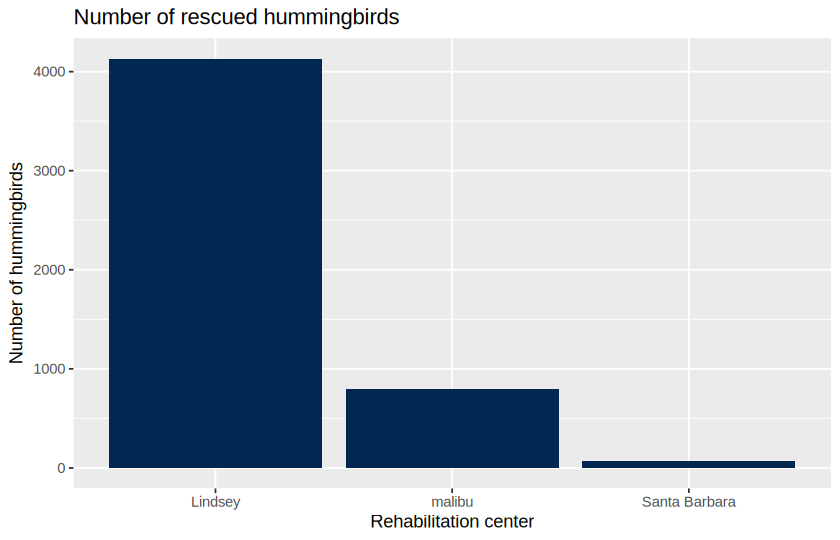

In [28]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [29]:
ggsave("outputs/rehab_counts_Edmunds.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer: p creates an object to store the graph in, ggplot is the function that creates a graph, rehab is the data we will be using, aes helps define the axes through x and y, the + adds another aspect to the graph, geom_col creates the bars, fill colors the bars, xlab and ylab labels the axis, labs(title) titles the graph, then p at the end will display the graph.**

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer: No this is likely because Lindsey recieved more hummingbirds, so looking at proportions of death rather then count may allow us to see a better picture of reality.**

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [30]:
df <- model_data %>%
  group_by(F_Aid, Age_e, r, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

F_Aid,Age_e,r,Disposition_binary,count
<chr>,<chr>,<chr>,<chr>,<int>
No,Nestling,caught by domestic animal,Died,17
No,Nestling,caught by domestic animal,Released,20
No,Nestling,found inside,Released,1
No,Nestling,found on the ground,Died,74
No,Nestling,found on the ground,Released,185
No,Nestling,nest-related,Died,153
No,Nestling,nest-related,Released,240
No,Nestling,unknown,Died,31
No,Nestling,unknown,Released,77


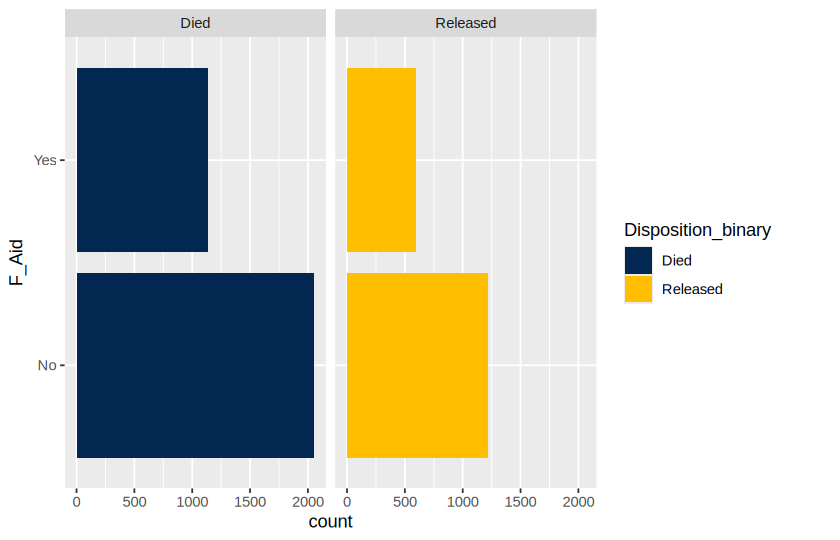

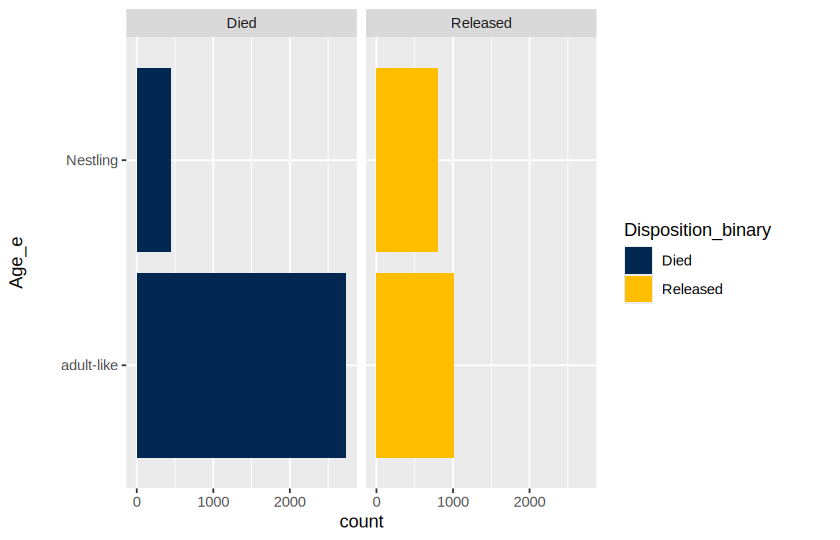

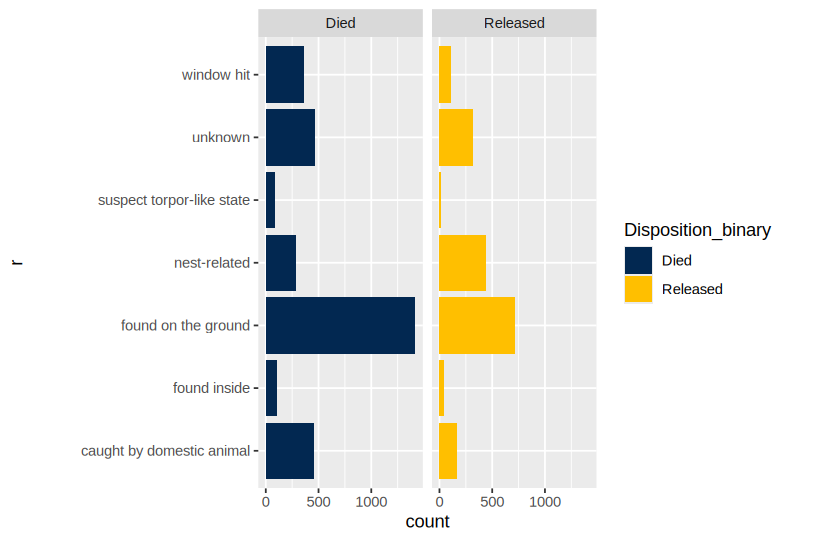

In [31]:
ggplot(df, aes(x = F_Aid, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))
ggplot(df, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))
ggplot(df, aes(x = r, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer: My tables and plots suggests higher death in with those with no first aid, adult-like, and found on the ground. There was higher release in those with no first aid, not much difference between age groups, and found on ground (with nest-related getting second highest release). I would say that age was associated with death and found on the ground also associated with death. To statistically check this we could run a chi-squared test.**

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2658,0.6435835
Lindsey,Released,1472,0.3564165
Santa Barbara,Died,42,0.6000000
Santa Barbara,Released,28,0.4000000
malibu,Died,487,0.6087500
malibu,Released,313,0.3912500


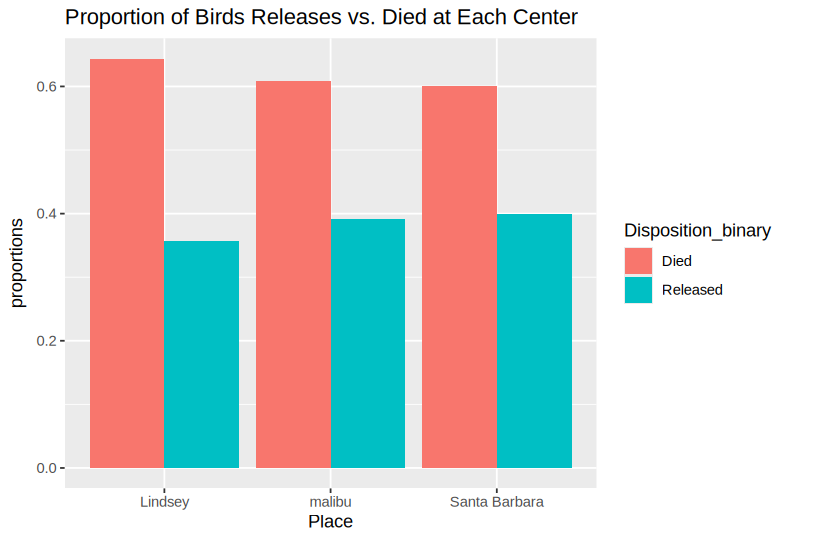

In [32]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Place") +
  ylab("proportions") +
  labs(title = "Proportion of Birds Releases vs. Died at Each Center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                
                 Non-selasphorus spp. Selasphorus spp.
  Non-selaphorus                 4115                0
  Selasphorus                       0              885

Species_group,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Non-selaphorus,Died,2642,0.5284
Non-selaphorus,Released,1473,0.2946
Selasphorus,Died,545,0.1090
Selasphorus,Released,340,0.0680


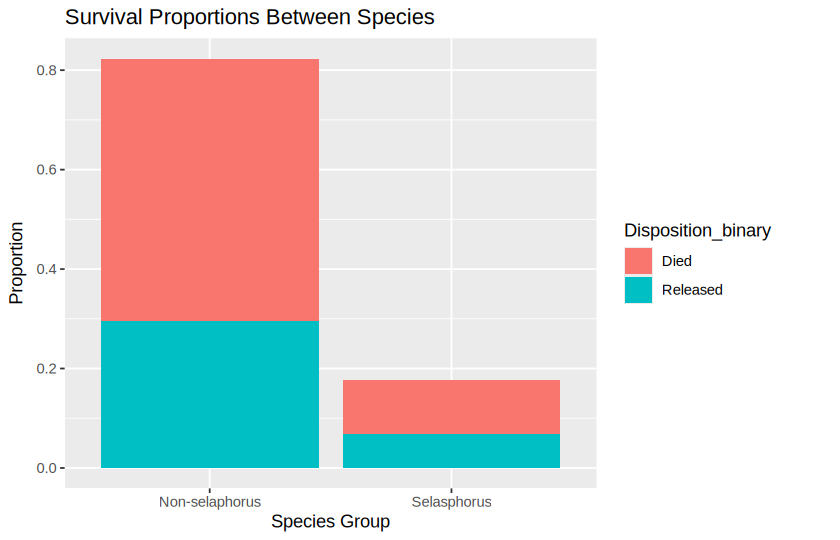

In [33]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selaphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count= n_distinct(ID), .groups="drop") %>%
  mutate(proportion= count/ sum(count))

species_distribution

ggplot(species_distribution, aes(x = Species_group, y = proportion, fill = Disposition_binary)) +
  geom_col() +
  xlab("Species Group") +
  ylab("Proportion") +
  labs(title = "Survival Proportions Between Species")

✍️ **Your answer: Yes, the non-selaphorus group had much higher proportion of death, and also higher proportion of released.**

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [34]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-21"

✍️ **Your answer: The format argument will format the data in the way requested, especially for dates it is important to format it in a way you will use so that when you sort and retreive it collects from your desired dates.**

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `spring` Why? Because the more people are outside during this time and there are more flowers being pollinated by the hummingbirds.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [44]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(count = n())

admissions_by_month

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count= n())

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_month and Species_group.
ℹ Output is grouped by Admitted_month.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_month, Species_group))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


Admitted_month,Species_group,count
<chr>,<chr>,<int>
1991-01,Non-selaphorus,12
1991-02,Non-selaphorus,3
1991-03,Non-selaphorus,19
1991-03,Selasphorus,4
1991-04,Non-selaphorus,22
1991-04,Selasphorus,4
1991-05,Non-selaphorus,18
1991-05,Selasphorus,3
1991-06,Non-selaphorus,21


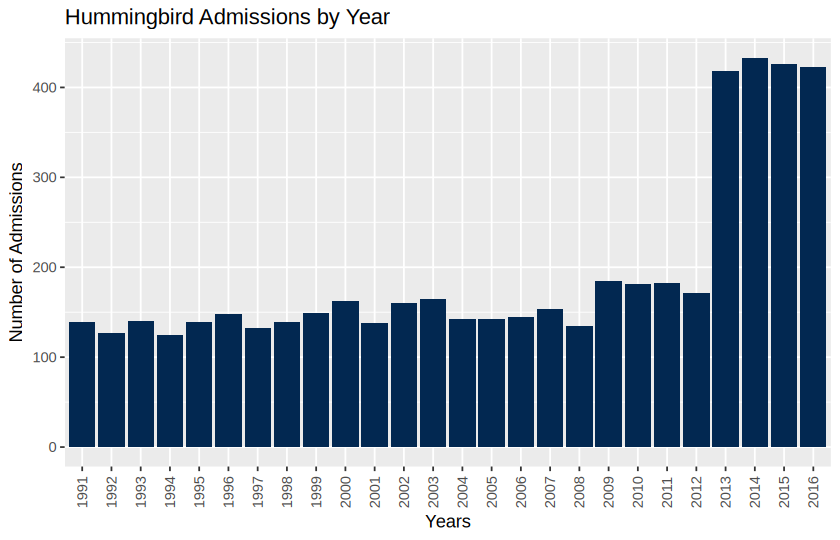

In [36]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Years") +
  ylab("Number of Admissions") +
  labs(title = "Hummingbird Admissions by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

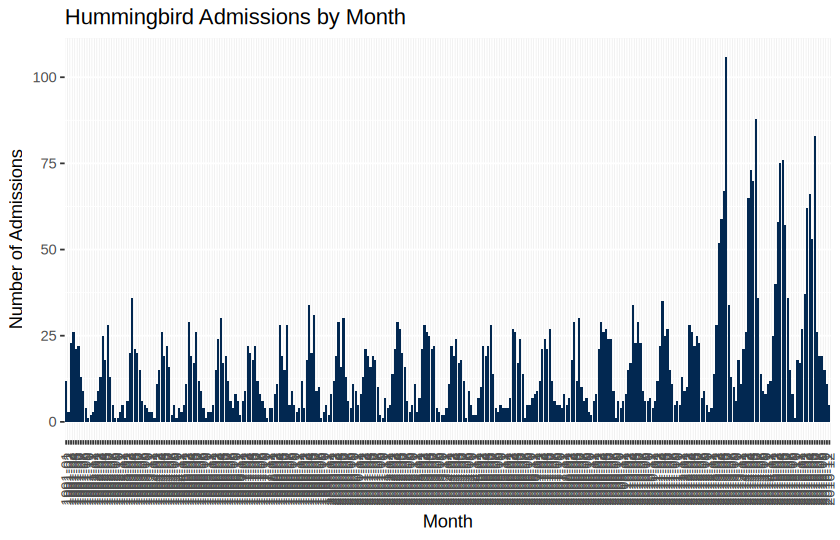

In [37]:

## now plot admissions_by_month the same way
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Month") +
  ylab("Number of Admissions") +
  labs(title = "Hummingbird Admissions by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

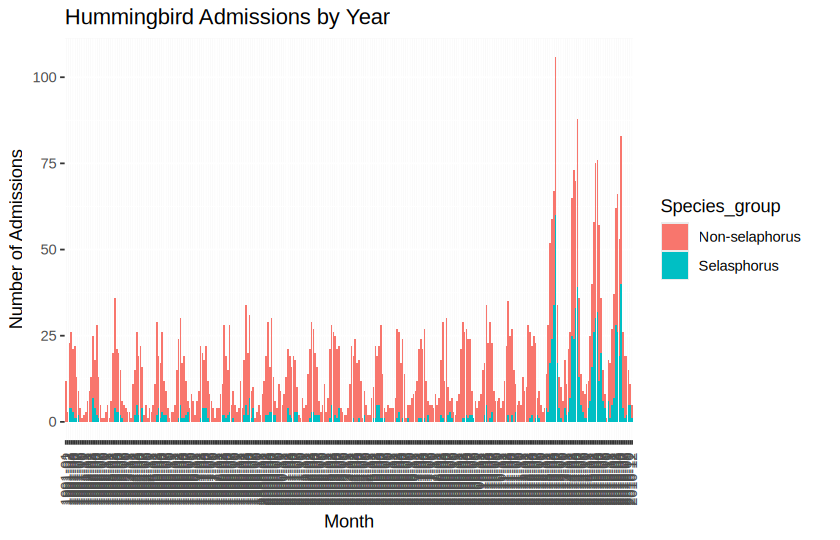

In [46]:
ggplot(admissions_by_month, aes(x = Admitted_month, y = count, fill = Species_group)) +
  geom_col() +
  xlab("Month") +
  ylab("Number of Admissions") +
  labs(title = "Hummingbird Admissions by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [39]:
# your investigation here
admissions_by_year_place <- model_data %>%
  count(Admitted_year_date = format(Admitted_date, "%Y"), Place)

admissions_by_year_place

Admitted_year_date,Place,n
<chr>,<chr>,<int>
1991,Lindsey,139
1992,Lindsey,127
1993,Lindsey,140
1994,Lindsey,125
1995,Lindsey,139
1996,Lindsey,148
1997,Lindsey,132
1998,Lindsey,139
1999,Lindsey,149


✍️ **Your answer: No, instead the other rehab centers opened and started accepting hummingbirds making collection rates higher.**

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [40]:
# your detective work here

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer: I was suprised by the amount of hummingbirds that received first aid from responders and the high proportion of non-selaphorus that died in the random 5000 sampled. I had a couple errors where I didn't match my terminology in the code and had to go back to make sure it all matched up.**

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [41]:
beep_colab("smb_stage_clear")   # mission complete 🍄